# Black-Scholes Option Pricing and Sensitivity Analysis

**Goal:** Price European call and put options with the Black-Scholes model, compute the Greeks, and study how the option price and the Greeks change when each input changes, and why.

## Contents
1. Baseline pricing
2. The Greeks
3. Price sensitivity to each parameter
4. Greeks as a function of the stock price
5. 3D surfaces
6. Validation: put-call parity
7. Conclusions
8. Assumptions, limitations and future work

## Notation

| Symbol | Meaning |
|---|---|
| S | Current stock price |
| K | Strike price |
| T | Time to maturity (in years) |
| r | Risk-free rate (annual, continuously compounded) |
| σ (`sigma`) | Annualized volatility |

**Baseline parameters:** S = 100, K = 100, T = 1 year, r = 5%, σ = 20%. In every sensitivity analysis only one parameter changes while the others stay at these values. These are illustrative numbers, not real market data.

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from scipy.stats import norm 

import os
os.makedirs("images", exist_ok=True)   # creates the folder if it does not exist
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

## Black-Scholes Model

For a European option on a stock that pays no dividends:

$$C = S\,N(d_1) - K e^{-rT} N(d_2)$$

$$P = K e^{-rT} N(-d_2) - S\,N(-d_1)$$

$$d_1 = \frac{\ln(S/K) + \left(r + \frac{\sigma^2}{2}\right)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$$

$N(\cdot)$ is the standard normal cumulative distribution function (`norm.cdf` in the code).

**Intuition for the call:** $S\,N(d_1)$ is the value of the stock received if the option is exercised, and $K e^{-rT} N(d_2)$ is the present value of the strike that must be paid. The call is the difference between the two.

The functions below are written with numpy, so they accept single numbers as well as arrays. This is what lets the sensitivity plots be drawn without loops.

In [2]:
def d1 (S , K , T , r , sigma ) :
    return (np.log(S/K) + (r + sigma**2 / 2) * T) / (sigma * T**0.5)

def d2 (S , K , T , r , sigma ) :
    return (np.log(S/K) + (r - sigma**2 / 2) * T) / (sigma * T**0.5)

In [3]:
def call_price (S , K , T , r , sigma ) :
    return (S * norm.cdf(d1(S,K,T,r,sigma))) - (K * np.exp(-r * T) * norm.cdf(d2(S,K,T,r,sigma)))

def put_price (S , K , T , r , sigma ) :
    return (K * np.exp(-r * T) * norm.cdf(-d2(S,K,T,r,sigma))) - (S * norm.cdf(-d1(S,K,T,r,sigma))) 

## 1. Baseline Pricing

Price of a call and a put that are **at-the-money** (S = K = 100), with T = 1 year, r = 5% and σ = 20%.

In [4]:
pd.DataFrame({
    'Call' : [call_price(100,100,1,0.05,0.2)],
    'Put' :[put_price(100,100,1,0.05,0.2)]
}, index = ['Price'] )

,Call,Put
Price,10.450584,5.573526


**Analysis**

- The call costs **10.45** and the put costs **5.57**.
- Because S = K, both options have zero intrinsic value (the payoff if exercised right now). The entire price is **time value**: what the market pays for the chance that the stock moves in the option's favor before maturity.
- The call is more expensive than the put because the risk-free rate is positive. By put-call parity the difference is $S - Ke^{-rT} = 4.88$. With r = 0 both options would cost the same, 7.97 (see section 3).

## 2. The Greeks

The Greeks measure how sensitive the option price is to each input. Each one is a derivative of the price.

| Greek | What it measures | Definition | Units used here |
|---|---|---|---|
| Delta | Change in option price for a 1-unit rise in S | $\partial V / \partial S$ | per 1 unit |
| Gamma | Change in Delta for a 1-unit rise in S | $\partial^2 V / \partial S^2$ | per 1 unit |
| Vega | Change in option price for a 1 percentage-point rise in σ | $\partial V / \partial \sigma$ | formula divided by 100 |
| Theta | Change in option price after one day passes | $-\partial V / \partial T$ | formula divided by 365 |
| Rho | Change in option price for a 1 percentage-point rise in r | $\partial V / \partial r$ | formula divided by 100 |

Here $V$ is the option price ($C$ for a call, $P$ for a put).

### Formulas

All formulas use the standard normal density

$$\varphi(x) = \frac{1}{\sqrt{2\pi}}\, e^{-x^2/2} \qquad (\text{`norm.pdf` in the code})$$

together with $d_1$, $d_2$ and $N(\cdot)$ from the model section.

**Delta**

$$\Delta_{\text{call}} = \frac{\partial C}{\partial S} = N(d_1), \qquad \Delta_{\text{put}} = \frac{\partial P}{\partial S} = N(d_1) - 1$$

**Gamma** (same for call and put)

$$\Gamma = \frac{\partial^2 C}{\partial S^2} = \frac{\varphi(d_1)}{S\,\sigma\sqrt{T}}$$

**Vega** (same for call and put)

$$\mathcal{V} = \frac{\partial C}{\partial \sigma} = S\,\varphi(d_1)\sqrt{T}$$

**Theta** (per year)

$$\Theta_{\text{call}} = -\frac{\partial C}{\partial T} = -\frac{S\,\varphi(d_1)\,\sigma}{2\sqrt{T}} - r K e^{-rT} N(d_2)$$

$$\Theta_{\text{put}} = -\frac{\partial P}{\partial T} = -\frac{S\,\varphi(d_1)\,\sigma}{2\sqrt{T}} + r K e^{-rT} N(-d_2)$$

**Rho**

$$\rho_{\text{call}} = \frac{\partial C}{\partial r} = K T e^{-rT} N(d_2), \qquad \rho_{\text{put}} = \frac{\partial P}{\partial r} = -K T e^{-rT} N(-d_2)$$

### Notes

- **Rescaling in the code:** Vega and Rho are divided by 100 (effect of a 1 percentage-point change), and Theta is divided by 365 (effect of one calendar day).
- **Sign of Theta:** $T$ is the time *remaining*, so as time passes $T$ decreases. That is why Theta is defined with a minus sign: it measures the change in price as time passes.
- **Why Gamma and Vega are the same for calls and puts:** put-call parity gives $C - P = S - Ke^{-rT}$. The right-hand side is linear in $S$ and does not depend on $\sigma$, so the second derivative with respect to $S$ and the derivative with respect to $\sigma$ are identical for the call and the put. The same relation also gives $\Delta_{\text{put}} = \Delta_{\text{call}} - 1$.

In [5]:
def delta_call(S, K, T, r, sigma):
    return norm.cdf(d1(S, K, T, r, sigma))

def delta_put(S, K, T, r, sigma):
    return norm.cdf(d1(S, K, T, r, sigma)) - 1

def gamma(S, K, T, r, sigma):
    return norm.pdf(d1(S, K, T, r, sigma)) / (S * sigma * T**0.5)

def vega(S, K, T, r, sigma):   # per 1% change in volatility
    return S * norm.pdf(d1(S, K, T, r, sigma)) * T**0.5 / 100

def theta_call(S, K, T, r, sigma):   # per day
    return (-(S * norm.pdf(d1(S, K, T, r, sigma)) * sigma) / (2 * T**0.5)
            - r * K * np.exp(-r * T) * norm.cdf(d2(S, K, T, r, sigma))) / 365

def theta_put(S, K, T, r, sigma):   # روزانه
    return (-(S * norm.pdf(d1(S, K, T, r, sigma)) * sigma) / (2 * T**0.5)
            + r * K * np.exp(-r * T) * norm.cdf(-d2(S, K, T, r, sigma))) / 365

def rho_call(S, K, T, r, sigma):   # per 1% change in rate
    return K * T * np.exp(-r * T) * norm.cdf(d2(S, K, T, r, sigma)) / 100

def rho_put(S, K, T, r, sigma):   # per 1% change in rate
    return -K * T * np.exp(-r * T) * norm.cdf(-d2(S, K, T, r, sigma)) / 100

In [6]:
def greeks_table(S, K, T, r, sigma):
    return pd.DataFrame({
        "Call": [delta_call(S, K, T, r, sigma), gamma(S, K, T, r, sigma),
                 vega(S, K, T, r, sigma), theta_call(S, K, T, r, sigma),
                 rho_call(S, K, T, r, sigma)],
        "Put":  [delta_put(S, K, T, r, sigma), gamma(S, K, T, r, sigma),
                 vega(S, K, T, r, sigma), theta_put(S, K, T, r, sigma),
                 rho_put(S, K, T, r, sigma)]
    }, index=["Delta", "Gamma", "Vega (per 1%)", "Theta (per day)", "Rho (per 1%)"])

greeks_table(100, 100, 1, 0.05, 0.2)

,Call,Put
Delta,0.636831,-0.363169
Gamma,0.018762,0.018762
Vega (per 1%),0.375240,0.375240
Theta (per day),-0.017573,-0.004542
Rho (per 1%),0.532325,-0.418905


**Analysis (S = K = 100)**

- **Delta:** a 1-unit rise in S raises the call by about **0.64** and lowers the put by about **0.36**.
- **Gamma:** **0.0188**. Delta itself changes by about 0.019 for a 1-unit move in S.
- **Vega:** **0.375**. If volatility rises from 20% to 21%, both options gain about 0.375.
- **Theta:** the call loses about **0.0176** per day and the put about **0.0045** per day. The put loses less because the interest-rate term in its Theta is positive, while in the call's Theta it is negative.
- **Rho:** a 1-percentage-point rise in r raises the call by about **0.53** and lowers the put by about **0.42**.

## 3. Price Sensitivity to Each Parameter

In each panel only one input changes and the others stay at their baseline values. In the first panel the dashed lines are the **payoff at maturity**: $\max(S-K,0)$ for the call and $\max(K-S,0)$ for the put.

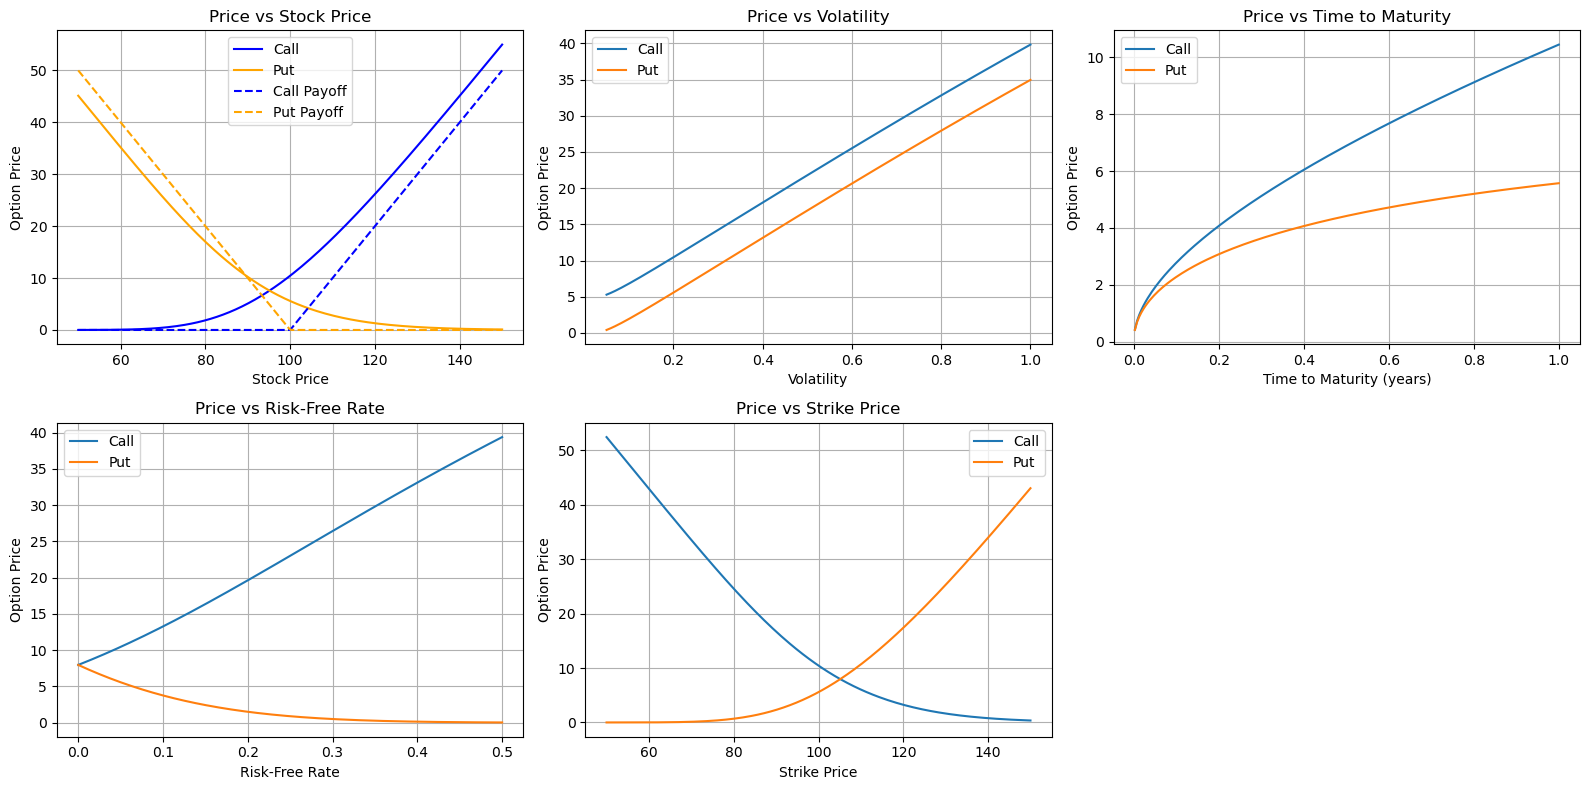

In [7]:
S0, K0, T0, r0, sigma0 = 100, 100, 1, 0.05, 0.2

S_range = np.linspace(50, 150, 200)
sigma_range = np.linspace(0.05, 1, 200)
T_range = np.linspace(1/365, 1, 200)
r_range = np.linspace(0, 0.5, 200)
K_range = np.linspace(50, 150, 200)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

# 1) stock price
axes[0, 0].plot(S_range, call_price(S_range, K0, T0, r0, sigma0), label="Call", color="blue")
axes[0, 0].plot(S_range, put_price(S_range, K0, T0, r0, sigma0), label="Put", color="orange")
axes[0, 0].plot(S_range, np.maximum(S_range - K0, 0), label="Call Payoff", color="blue", linestyle="--")
axes[0, 0].plot(S_range, np.maximum(K0 - S_range, 0), label="Put Payoff", color="orange", linestyle="--")
axes[0, 0].set_title("Price vs Stock Price")
axes[0, 0].set_xlabel("Stock Price")

# 2) volatility
axes[0, 1].plot(sigma_range, call_price(S0, K0, T0, r0, sigma_range), label="Call")
axes[0, 1].plot(sigma_range, put_price(S0, K0, T0, r0, sigma_range), label="Put")
axes[0, 1].set_title("Price vs Volatility")
axes[0, 1].set_xlabel("Volatility")

# 3) time to maturity 
axes[0, 2].plot(T_range, call_price(S0, K0, T_range, r0, sigma0), label="Call")
axes[0, 2].plot(T_range, put_price(S0, K0, T_range, r0, sigma0), label="Put")
axes[0, 2].set_title("Price vs Time to Maturity")
axes[0, 2].set_xlabel("Time to Maturity (years)")

# 4) risk-free rate
axes[1, 0].plot(r_range, call_price(S0, K0, T0, r_range, sigma0), label="Call")
axes[1, 0].plot(r_range, put_price(S0, K0, T0, r_range, sigma0), label="Put")
axes[1, 0].set_title("Price vs Risk-Free Rate")
axes[1, 0].set_xlabel("Risk-Free Rate")

# 5) strike price
axes[1, 1].plot(K_range, call_price(S0, K_range, T0, r0, sigma0), label="Call")
axes[1, 1].plot(K_range, put_price(S0, K_range, T0, r0, sigma0), label="Put")
axes[1, 1].set_title("Price vs Strike Price")
axes[1, 1].set_xlabel("Strike Price")

# we turn off the 6th panel
axes[1, 2].axis("off")

for ax in list(axes.flat)[:5]:
    ax.set_ylabel("Option Price")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.savefig("images/01_price_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

**Analysis of each panel**

1. **Stock price (S):** the call rises with S and the put falls. The call always stays above its payoff, and the gap is its time value, which is largest near S = K. **The put drops below its payoff for S below about 89.5.** This is not an error. A European put can only be exercised at maturity, so the amount $K - S$ is received a year from now and its present value is discounted. A deep in-the-money put is worth roughly $Ke^{-rT} - S$, which is $K(1-e^{-rT}) \approx 4.88$ below $K - S$. An American put does not have this property because it can be exercised at any time.
2. **Volatility (σ):** both prices rise with volatility, because a buyer's loss is limited to the premium while the potential gain grows with larger price moves. The call and put curves are parallel, since Vega is the same for both. Their gap stays at 4.88 for every σ, because put-call parity does not depend on σ. With σ = 5% the prices are about 5.28 and 0.41, and with σ = 100% they are about 39.84 and 34.96.
3. **Time to maturity (T):** both prices rise with T for these parameters. The curve looks like a square root because volatility scales with $\sqrt{T}$. The slope is steepest at the start, which means time value erodes fastest in the last days before maturity.
4. **Risk-free rate (r):** the call rises with r and the put falls, because the present value of the strike shrinks. At r = 0 both cost 7.97. At r = 50% the call is 39.38 and the put is 0.03. At low rates the effect is small, but at high rates it is large.
5. **Strike price (K):** the call falls as K rises and the put rises. The two curves cross at $K = Se^{rT} \approx 105.1$, where parity says call and put prices are equal.

## 4. Greeks as a Function of the Stock Price

All five Greeks (Delta, Gamma, Vega, Theta and Rho) plotted against S, with K = 100, T = 1, r = 5% and σ = 20%.

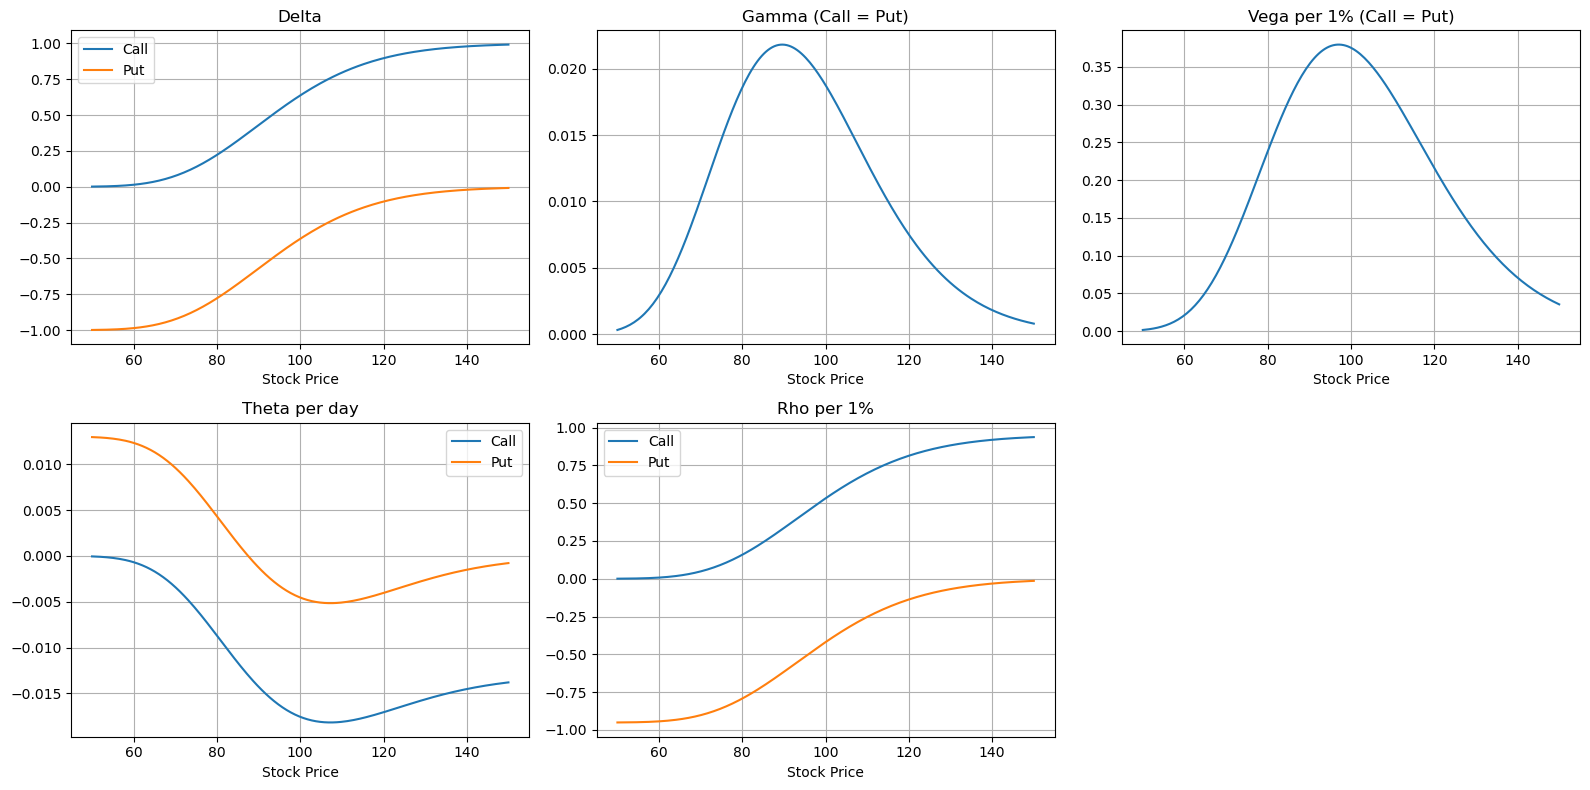

In [8]:
S_range = np.linspace(50, 150, 200)
K0, T0, r0, sigma0 = 100, 1, 0.05, 0.2

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

# Delta
axes[0, 0].plot(S_range, delta_call(S_range, K0, T0, r0, sigma0), label="Call")
axes[0, 0].plot(S_range, delta_put(S_range, K0, T0, r0, sigma0), label="Put")
axes[0, 0].set_title("Delta")

# Gamma
axes[0, 1].plot(S_range, gamma(S_range, K0, T0, r0, sigma0))
axes[0, 1].set_title("Gamma (Call = Put)")

# Vega
axes[0, 2].plot(S_range, vega(S_range, K0, T0, r0, sigma0))
axes[0, 2].set_title("Vega per 1% (Call = Put)")

# Theta
axes[1, 0].plot(S_range, theta_call(S_range, K0, T0, r0, sigma0), label="Call")
axes[1, 0].plot(S_range, theta_put(S_range, K0, T0, r0, sigma0), label="Put")
axes[1, 0].set_title("Theta per day")

# Rho
axes[1, 1].plot(S_range, rho_call(S_range, K0, T0, r0, sigma0), label="Call")
axes[1, 1].plot(S_range, rho_put(S_range, K0, T0, r0, sigma0), label="Put")
axes[1, 1].set_title("Rho per 1%")

# we turn off the 6th panel
axes[1, 2].axis("off")

for ax in list(axes.flat)[:5]:
    ax.set_xlabel("Stock Price")
    ax.grid(True)

axes[0, 0].legend()
axes[1, 0].legend()
axes[1, 1].legend()

plt.tight_layout()
plt.savefig("images/02_greeks_vs_stock_price.png", dpi=150, bbox_inches="tight")
plt.show()

**Analysis**

**Delta**
- The curves are S-shaped. The call's Delta rises from about 0 (S = 50: 0.001) to about 1 (S = 150: 0.991), and the put's Delta runs from −1 to 0. The two curves are always exactly 1 apart, because $\Delta_{\text{put}} = \Delta_{\text{call}} - 1$.
- The call's Delta equals 0.5 not at S = K but at $S = Ke^{-(r+\sigma^2/2)T} \approx 93.2$. At S = K it is **0.64**, because $d_1 = 0.35$ there: in the model the stock drifts upward at an average rate of $r + \sigma^2/2$.
- Delta is the hedge ratio. To hedge one short call at S = K you hold about 0.64 shares. At S = 80 you need only 0.22 shares per call, while at S = 120 you need 0.90.
- Delta is sometimes read loosely as the probability that the option finishes in the money. That is only approximate. The exact risk-neutral probability for the call is $N(d_2)$, which is 0.56 at S = K, lower than Delta.

**Gamma**
- Bell-shaped, with its peak at **S ≈ 89.6** (value 0.022). In this model the peak sits at $S = Ke^{-(r+1.5\sigma^2)T}$, which is left of K. At S = 60, 100 and 140 Gamma is 0.003, 0.019 and 0.002.
- Gamma is the slope of Delta, so it is largest where Delta changes fastest. Deep in or out of the money, Delta is nearly flat at 0 or 1, and Gamma is close to zero.
- High Gamma means a hedge must be adjusted often, because Delta moves a lot when the stock moves. Option buyers are long Gamma and benefit from large moves. Sellers are short Gamma and are exposed to them. Buyers pay for this through time decay: the region with high Gamma is also where Theta is large and negative.

**Vega**
- Bell-shaped, with its peak at **S ≈ 97** (value 0.379), given by $S = Ke^{-(r-\sigma^2/2)T}$, just below K. At S = 100 it is 0.375.
- Only options near the money are really sensitive to volatility. At S = 60 Vega is 0.021, about 18 times smaller than at the peak, and at S = 140 it is 0.071. Vega is higher on the right than on the left, because the stock needs a smaller relative move to reach the money from 140 than from 60.
- Vega is the same for calls and puts, since put-call parity does not involve σ.
- Vega also depends on maturity. For an at-the-money option, Vega is 0.375 with T = 1 year, 0.196 with T = 0.25 and 0.125 with T = 0.1. Long-dated options are more exposed to changes in volatility.

**Theta**
- **Call:** always negative. It is about 0 for deep out-of-the-money calls (S = 50), most negative around **S ≈ 107** (about −0.018 per day), and levels off near −0.013 to −0.014 deep in the money. In that region the call is roughly $S - Ke^{-rT}$, and the present value of the strike grows with time at rate $r$, so its value falls by about $rKe^{-rT}/365 = 0.013$ per day.
- **Put:** negative near the money (−0.0045 per day at S = 100), but **positive for S below about 87.5**. At S = 50 it is +0.013 per day, which is exactly $rKe^{-rT}/365$. A deep in-the-money European put trades below its payoff and moves up toward it as maturity approaches, so its value rises as time passes. This is the same effect seen in section 3.
- Time decay is not constant. For the at-the-money call, Theta is −0.018 per day with T = 1 year, but −0.029 with T = 0.25, −0.041 with T = 0.1 and −0.084 with T = 0.02. Today's decay (0.018 per day) is below the average over the whole year (10.45 / 365 ≈ 0.029 per day), because decay accelerates near maturity.

**Rho**
- S-shaped, like Delta. The call's Rho rises from about 0 (deep out of the money) to about **0.95** (deep in the money), and the put's Rho goes from about −0.95 to 0. At S = 80 they are 0.16 and −0.79, at S = K they are 0.53 and −0.42, and at S = 120 they are 0.81 and −0.14.
- A deep in-the-money call is almost certain to be exercised, so it behaves like a stock bought with a loan of $K$ repaid at maturity. A higher rate lowers the present value of that strike, which benefits the call. A deep out-of-the-money call has almost no exposure to r. The put mirrors this.
- The gap between the two curves is constant at $KTe^{-rT}/100 \approx 0.95$ for every S, because the right-hand side of put-call parity, $S - Ke^{-rT}$, depends on r only through the strike term.
- Rho scales with T. For the at-the-money call it is 0.53 with T = 1 year, 0.13 with T = 0.25 and 0.05 with T = 0.1. For a 1-year option, a 1-percentage-point rate move matters more than a 1-point volatility move (0.53 versus 0.375 at S = K), but interest rates usually move far less than volatility. So Rho often matters least for short-dated options, and more for long maturities and in high-rate environments.

## 5. 3D Surfaces

When a price or Greek depends on **two** inputs, we get a surface instead of a line. The horizontal axes are the stock price S and the time to maturity T, and the height is the call price (left) or Gamma (right). `np.meshgrid` builds every combination of S and T (an 80×80 grid, 6,400 points), and the functions are evaluated on the whole grid at once.

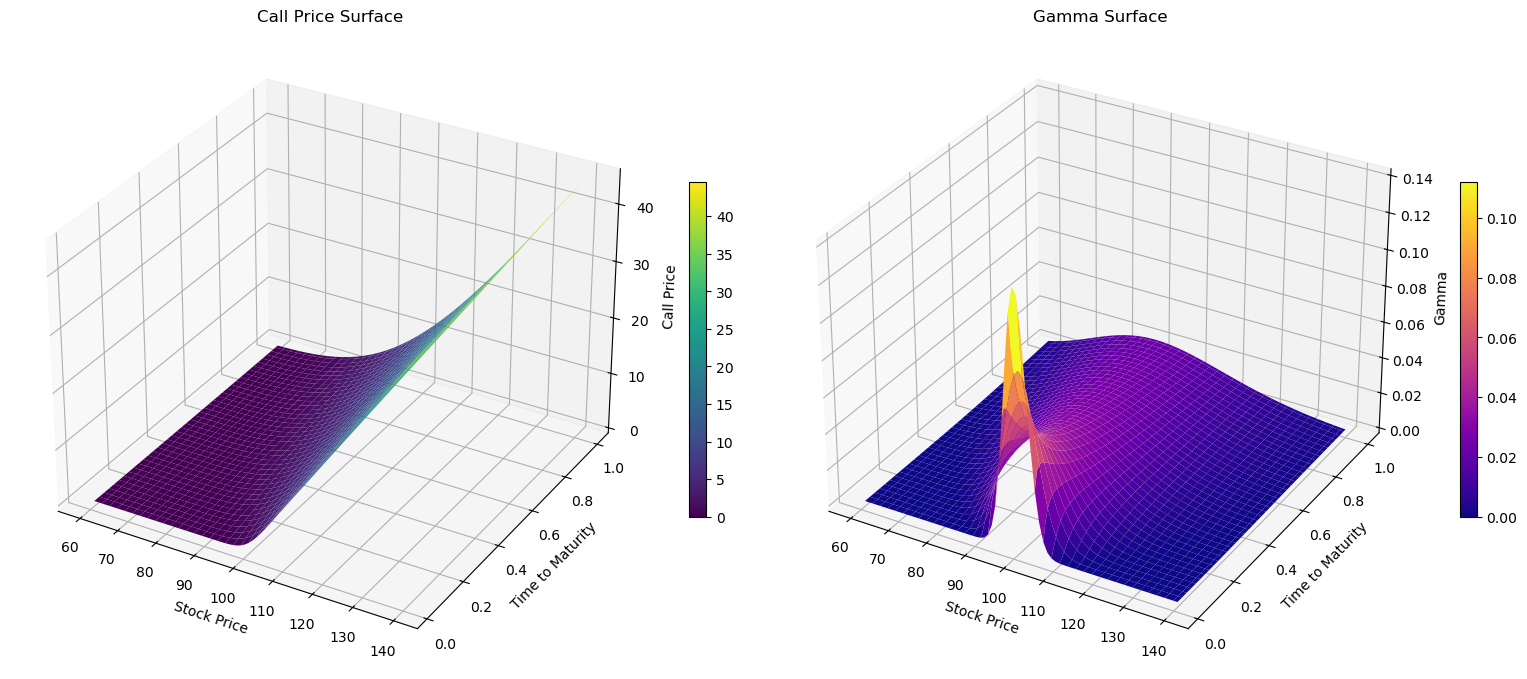

In [9]:
K0, r0, sigma0 = 100, 0.05, 0.2

S_vals = np.linspace(60, 140, 80)
T_vals = np.linspace(0.02, 1, 80)

# creating two 80x80 arrays
S_grid, T_grid = np.meshgrid(S_vals, T_vals)

call_surface = call_price(S_grid, K0, T_grid, r0, sigma0)
gamma_surface = gamma(S_grid, K0, T_grid, r0, sigma0)

fig = plt.figure(figsize=(16, 7))

# 1) call price surface
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
surf1 = ax1.plot_surface(S_grid, T_grid, call_surface, cmap="viridis")
ax1.set_title("Call Price Surface")
ax1.set_xlabel("Stock Price")
ax1.set_ylabel("Time to Maturity")
ax1.set_zlabel("Call Price")
fig.colorbar(surf1, ax=ax1, shrink=0.5)

# 2) Gamma surface
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
surf2 = ax2.plot_surface(S_grid, T_grid, gamma_surface, cmap="plasma")
ax2.set_title("Gamma Surface")
ax2.set_xlabel("Stock Price")
ax2.set_ylabel("Time to Maturity")
ax2.set_zlabel("Gamma")
fig.colorbar(surf2, ax=ax2, shrink=0.5)

plt.tight_layout()
plt.savefig("images/03_3d_surfaces.png", dpi=150, bbox_inches="tight")
plt.show()

**Analysis**

- **Call price surface:** for large T the surface is smooth and curved. As T approaches zero it collapses toward the kinked payoff $\max(S-K,0)$. This is the **erosion of time value**.
- **Gamma surface:** with T = 1 the peak is about 0.022 near S ≈ 90. With T = 0.02 the peak rises to about **0.14** (roughly 6.5 times higher) and moves to S ≈ 100, right at the strike. So close to maturity and close to K, Delta changes very abruptly. Hedging such an option is harder and more costly, which is why short-dated at-the-money options are considered risky.

## 6. Validation: Put-Call Parity

For a European option on a stock with no dividends, the following must always hold:

$$C - P = S - K e^{-rT}$$

The left side is computed from our own functions and the right side from the theoretical formula. `np.isclose` is used for the comparison, because two floating-point numbers that are mathematically equal can differ in the last decimal places. The check is run once for a single point and once for 200 different stock prices.

In [10]:
S0, K0, T0, r0, sigma0 = 100, 100, 1, 0.05, 0.2

parity = call_price (S0 , K0 , T0 , r0 , sigma0 ) - put_price (S0 , K0 , T0 , r0 , sigma0 )
theoretical_parity = S0 - K0 * np.exp(-r0*T0)

print('call - put :', parity)
print('S - K*e^(-rT) :', theoretical_parity)
print('parity holds :', np.isclose(parity,theoretical_parity))

call - put : 4.877057549928594
S - K*e^(-rT) : 4.877057549928594
parity holds : True


In [11]:
S_range = np.linspace(50, 150, 200)

parity_array = call_price(S_range, K0, T0, r0, sigma0) - put_price(S_range, K0, T0, r0, sigma0)
theoretical_array = S_range - K0 * np.exp(-r0 * T0)

print('parity holds on 200 different prices :',np.allclose(parity_array, theoretical_array))

parity holds on 200 different prices : True


**Result**

Both checks return `True`, so `call_price` and `put_price` are consistent with each other. The baseline prices (10.4506 and 5.5735) also match the well-known reference values for these inputs.

Parity only holds under the model's assumptions (European exercise, no dividends). On real market data, a violation would point to dividends, transaction costs or illiquidity rather than a coding error.

## 7. Conclusions

- **Price structure:** an option's price is made of intrinsic value and time value. S and K determine intrinsic value, while volatility and time create time value. The risk-free rate has a small effect at low levels but a large one at high levels.
- **Consistency check:** put-call parity held at one point and across 200 stock prices.
- **Greeks as risk measures:** Delta is the sensitivity to the stock, Gamma is how stable Delta is, Vega is the sensitivity to volatility, Theta is the cost of time passing, and Rho is the sensitivity to interest rates.
- **Where each risk is largest:** Gamma is greatest for options close to maturity and close to the strike, and Vega is greatest for at-the-money options. Theta grows more negative as maturity approaches. Rho grows with maturity and with the level of interest rates, so it matters most for long-dated options and in high-rate environments.
- **Calls and puts:** Gamma and Vega are the same for both, while Delta and Rho differ by a constant ($\Delta_{\text{call}} - \Delta_{\text{put}} = 1$ and $\rho_{\text{call}} - \rho_{\text{put}} = KTe^{-rT}/100$). Both follow from put-call parity.

## 8. Assumptions, Limitations and Future Work

**Model assumptions**
- The option is **European** (exercised only at maturity).
- The stock pays **no dividends**.
- Volatility and the risk-free rate are **constant**.
- The stock price follows a geometric Brownian motion (log-normal returns), and trading is continuous, costless and free of short-selling restrictions.

**Limitations of this project**
- All results use illustrative parameters. No real market data is used.
- Volatility is an input here. In real markets, implied volatility differs across strikes and maturities (the volatility smile), which conflicts with the constant-volatility assumption.
- Applying the model to a real market requires checking the contract specifications (exercise style, dividends, settlement) and the liquidity of the options.

**Possible extensions**
- Compute implied volatility from real option prices and compare it with historical volatility.
- Price the same options with Monte Carlo simulation and compare with the closed-form result.
- Estimate volatility from the returns of a real stock.
- Plot strategy payoffs (straddle, covered call) and simulate delta hedging.